# 01 — Exploratory Data Analysis & STL Decomposition (PJM East)

Inspects 16+ years of hourly electricity demand (`PJME_hourly.csv`), resolves Daylight Saving Time anomalies, tests stationarity (ADF), and decomposes daily demand via STL.

In [1]:
from pathlib import Path
import urllib.request

# Colab-friendly setup: ensures src modules and PJME CSV are available
if not Path('src/data.py').exists():
    import subprocess
    subprocess.run(['git', 'clone', 'https://github.com/GaneshArwan/time_series_energy_demand.git', 'repo'], check=True)
    import os
    os.chdir('repo')

data_path = Path('data/PJME_hourly.csv')
if not data_path.exists():
    data_path.parent.mkdir(parents=True, exist_ok=True)
    url = 'https://raw.githubusercontent.com/panambY/Hourly_Energy_Consumption/refs/heads/master/data/PJME_hourly.csv'
    urllib.request.urlretrieve(url, data_path)
print(f'Dataset ready: {data_path} ({data_path.stat().st_size:,} bytes)')

Dataset ready: data\PJME_hourly.csv (4,070,265 bytes)


In [2]:
import json
import matplotlib.pyplot as plt
import pandas as pd
from statsmodels.tsa.stattools import adfuller
from src.data import load_pjm_series

df, summary = load_pjm_series('PJME_hourly.csv')
print(json.dumps(summary, indent=2))
df.head()

{
  "region": "PJME",
  "raw_rows": 145366,
  "clean_rows": 145392,
  "duplicates_resolved": 4,
  "gaps_interpolated": 30,
  "start_date": "2002-01-01T01:00:00",
  "end_date": "2018-08-03T00:00:00",
  "min_mw": 14544.0,
  "median_mw": 31420.0,
  "mean_mw": 32078.93,
  "max_mw": 62009.0
}


,ds,y
0,2002-01-01 01:00:00,30393.0
1,2002-01-01 02:00:00,29265.0
2,2002-01-01 03:00:00,28357.0
3,2002-01-01 04:00:00,27899.0
4,2002-01-01 05:00:00,28057.0


Daily Mean ADF Statistic: -8.8735, p-value: 0.000000


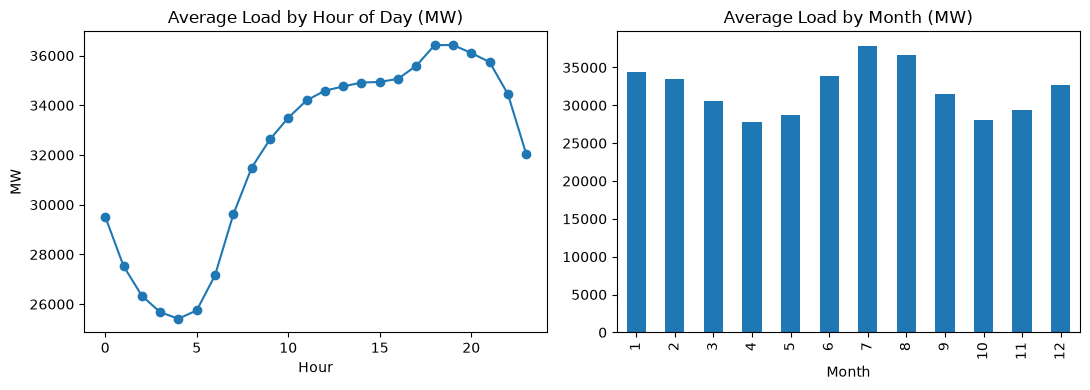

In [3]:
daily = df.set_index('ds')['y'].resample('D').mean()
adf_stat, p_val, *_ = adfuller(daily.dropna(), maxlag=30, result_object=False)
print(f'Daily Mean ADF Statistic: {adf_stat:.4f}, p-value: {p_val:.6f}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4), dpi=100)
df.assign(hour=df['ds'].dt.hour).groupby('hour')['y'].mean().plot(ax=axes[0], marker='o')
axes[0].set_title('Average Load by Hour of Day (MW)')
axes[0].set_xlabel('Hour')
axes[0].set_ylabel('MW')

df.assign(month=df['ds'].dt.month).groupby('month')['y'].mean().plot(kind='bar', ax=axes[1])
axes[1].set_title('Average Load by Month (MW)')
axes[1].set_xlabel('Month')
plt.tight_layout()
plt.show()

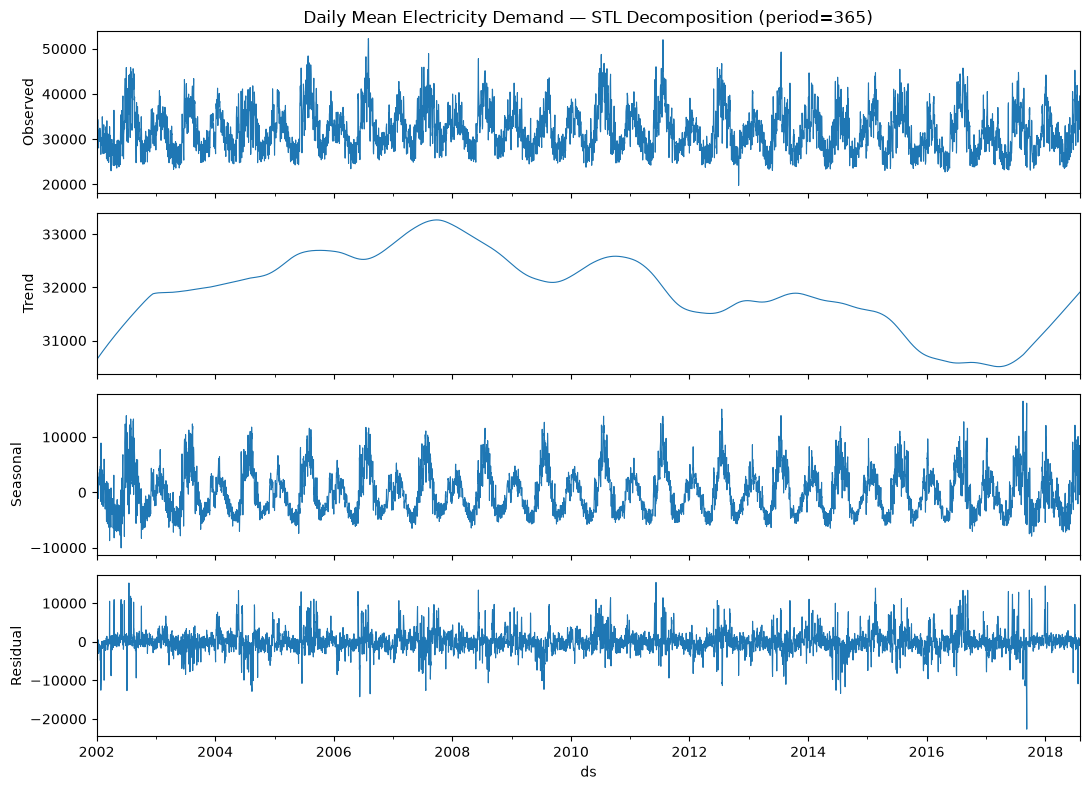

In [4]:
stl_df = pd.read_csv('artifacts/decomposition_daily.csv', parse_dates=['ds']).set_index('ds')
fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True, dpi=100)
for ax, col, label in zip(axes, ['observed', 'trend', 'seasonal', 'residual'], ['Observed', 'Trend', 'Seasonal', 'Residual']):
    stl_df[col].plot(ax=ax, linewidth=0.8)
    ax.set_ylabel(label)
axes[0].set_title('Daily Mean Electricity Demand — STL Decomposition (period=365)')
plt.tight_layout()
plt.show()